In [ ]:
from alpaca.data.historical import StockHistoricalDataClient
from alpaca.data.requests import StockBarsRequest
from alpaca.data.timeframe import TimeFrame
import pandas as pd
from datetime import datetime
from pathlib import Path
from env import API_KEY, SECRET_KEY

# Usar caché local para evitar límites de la API de Alpaca
csv_path = Path("aapl_raw.csv")

if csv_path.exists():
    df = pd.read_csv(csv_path, parse_dates=["timestamp"])
    print(f"Datos cargados desde CSV local: {csv_path} ({len(df)} registros)")
else:
    client = StockHistoricalDataClient(API_KEY, SECRET_KEY)

    request_params = StockBarsRequest(
        symbol_or_symbols="AAPL",
        timeframe=TimeFrame.Day,
        start=datetime(2020, 1, 1),
        end=datetime(2026, 3, 25)
    )

    bars = client.get_stock_bars(request_params)
    df = bars.df.reset_index()
    df.to_csv(csv_path, index=False)
    print(f"Datos descargados y guardados en: {csv_path} ({len(df)} registros)")

assert len(df) > 800, f"Total de registro obtenidos: {len(df)}"
df.head()

Datos cargados desde CSV local: aapl_raw.csv (1564 registros)


,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,AAPL,2020-01-02 05:00:00+00:00,296.24,300.6000,295.190,300.35,36554338.0,283489.0,298.546196
1,AAPL,2020-01-03 05:00:00+00:00,297.15,300.5800,296.500,297.43,38677814.0,280441.0,298.834372
2,AAPL,2020-01-06 05:00:00+00:00,293.79,299.9600,292.750,299.80,31399992.0,242868.0,297.813476
3,AAPL,2020-01-07 05:00:00+00:00,299.84,300.9000,297.480,298.39,29556784.0,227871.0,299.034972
4,AAPL,2020-01-08 05:00:00+00:00,297.16,304.4399,297.156,303.19,35684201.0,261773.0,301.304133


In [48]:
from sklearn.preprocessing import StandardScaler

# Seleccionar columnas relevantes
features = ['open', 'high', 'low', 'volume', 'vwap', 'trade_count']

# Feature Engineering: Promedios móviles de 5 y 10 días
df['SMA_5'] = df['close'].rolling(window=5).mean()
df['SMA_10'] = df['close'].rolling(window=10).mean()

features.extend(['SMA_5', 'SMA_10'])

# Variable objetivo (Precio de cierre del día siguiente)
df['Target'] = df['close'].shift(-1)

df = df.dropna()

X = df[features]
y = df['Target']

# Normalización (Estandarización)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print(f"Registros después de la limpieza: {len(X_scaled_df)}")
X_scaled_df.head()

Registros después de la limpieza: 1554


,open,high,low,volume,vwap,trade_count,SMA_5,SMA_10
0,1.777500,1.775699,1.793565,-1.069706,1.788161,-1.511816,1.788080,1.707099
1,1.804237,1.778734,1.833019,-1.147020,1.806861,-1.737357,1.805416,1.730321
2,1.845418,1.824861,1.878221,-0.904076,1.850178,-1.616384,1.831375,1.763541
3,1.859555,1.829109,1.893754,-1.088970,1.855140,-1.731436,1.830170,1.789695
4,1.880914,1.843827,1.914102,-1.186241,1.872774,-1.733896,1.845683,1.819811


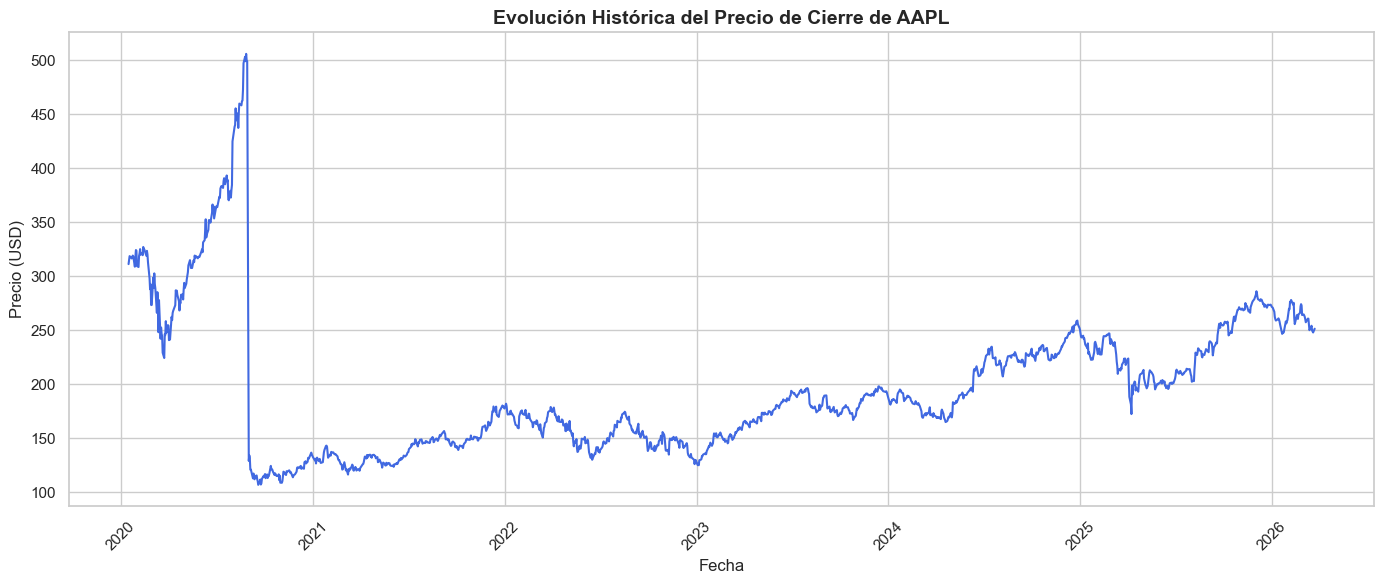

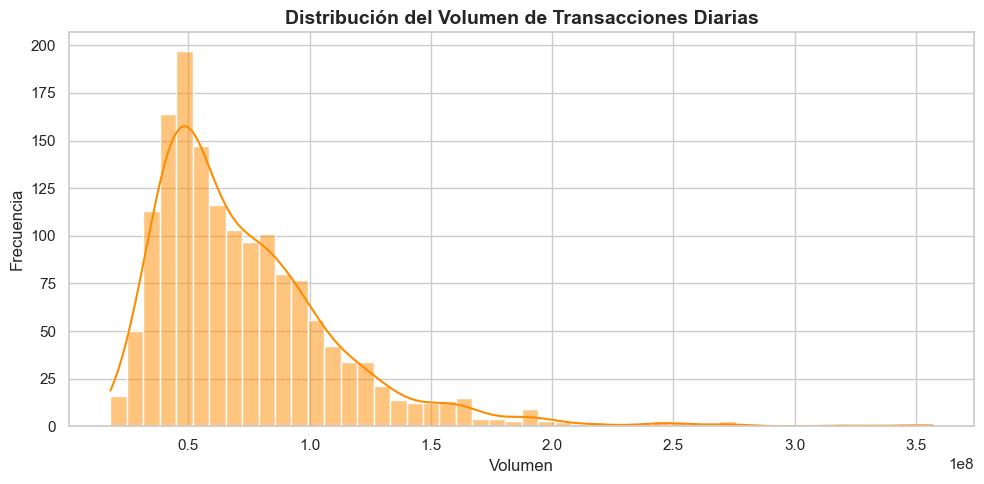

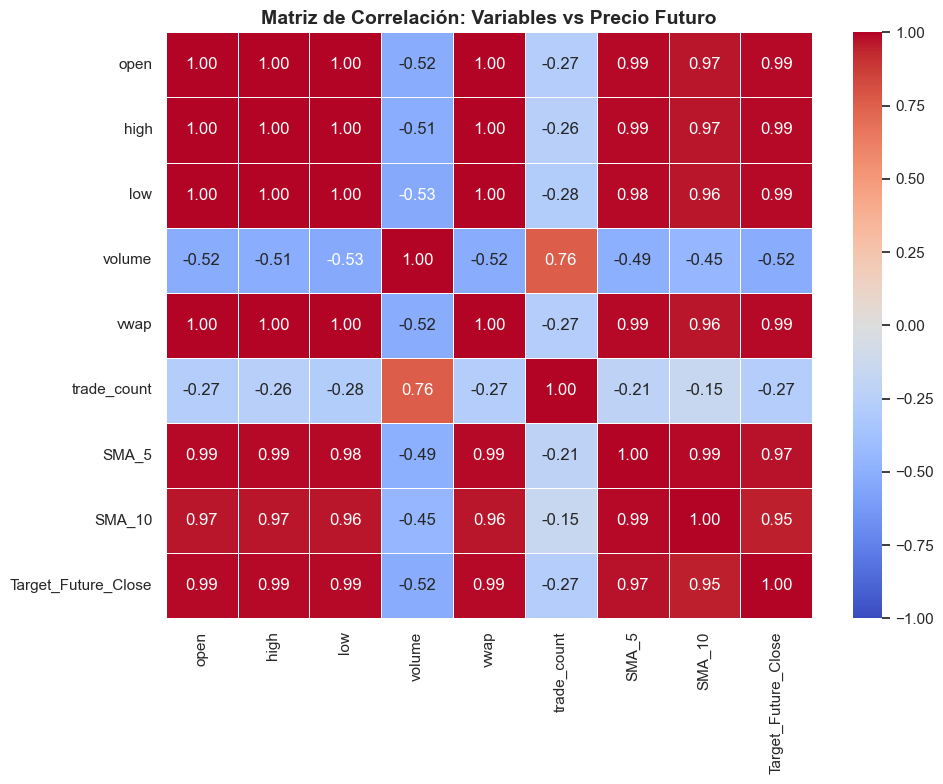

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual de las gráficas
sns.set_theme(style="whitegrid")

# 1. Evolución Histórica del Precio (Análisis Bivariado)
plt.figure(figsize=(14, 6))
plt.plot(df['timestamp'], df['close'], color='royalblue', linewidth=1.5)
plt.title('Evolución Histórica del Precio de Cierre de AAPL', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Distribución del Volumen de Transacciones (Análisis Univariado)
plt.figure(figsize=(10, 5))
sns.histplot(df['volume'], bins=50, kde=True, color='darkorange')
plt.title('Distribución del Volumen de Transacciones Diarias', fontsize=14, fontweight='bold')
plt.xlabel('Volumen', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Mapa de Calor de Correlación (Análisis Multivariado)
eda_df = X_scaled_df.copy()
eda_df['Target_Future_Close'] = y.values

plt.figure(figsize=(10, 8))

correlation_matrix = eda_df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación: Variables vs Precio Futuro', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, BayesianRidge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# División de datos (80% train, 20% test)x
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, shuffle=False)

# Diccionario con los 8 modelos solicitados 
models = {
    "OLS Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1),
    "Bayesian Regression": BayesianRidge(),
    "KNN Regression": KNeighborsRegressor(n_neighbors=5),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVM Regression": SVR(kernel='rbf', C=100, gamma=0.1),
    "MLP Regression": MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
}

trained_models = {}

# Entrenamiento
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} entrenado exitosamente.")

OLS Regression entrenado exitosamente.
Ridge Regression entrenado exitosamente.
Lasso Regression entrenado exitosamente.
Bayesian Regression entrenado exitosamente.
KNN Regression entrenado exitosamente.


c:\Users\ronny\source\repos\AAPL-Stock-Prediction-ML-Pipeline\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.868e+02, tolerance: 5.722e+02
  model = cd_fast.enet_coordinate_descent(


Random Forest entrenado exitosamente.
SVM Regression entrenado exitosamente.
MLP Regression entrenado exitosamente.


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False)
print(results_df)

                 Model       MAE        MSE      RMSE        R2
1     Ridge Regression  3.199007  20.015776  4.473899  0.971439
3  Bayesian Regression  3.207662  20.171395  4.491258  0.971217
0       OLS Regression  3.340871  20.870141  4.568385  0.970220
2     Lasso Regression  3.455454  21.989700  4.689318  0.968623
6       SVM Regression  3.792161  26.379945  5.136141  0.962358
7       MLP Regression  3.743208  27.613370  5.254843  0.960598
5        Random Forest  4.554160  36.273969  6.022787  0.948241
4       KNN Regression  6.229508  61.317621  7.830557  0.912506


In [53]:
def predecir_nuevo_csv(ruta_csv, mejor_modelo, scaler_entrenado):
    nuevos_datos = pd.read_csv(ruta_csv, parse_dates=["timestamp"])
    
    nuevos_datos['SMA_5'] = nuevos_datos['close'].rolling(window=5).mean()
    nuevos_datos['SMA_10'] = nuevos_datos['close'].rolling(window=10).mean()
    nuevos_datos = nuevos_datos.dropna()
    
    X_nuevos = nuevos_datos[features]
    
    X_nuevos_scaled = scaler_entrenado.transform(X_nuevos)
    
    # Predecir
    predicciones = mejor_modelo.predict(X_nuevos_scaled)
    nuevos_datos['Prediccion_Futura'] = predicciones
    
    return nuevos_datos[['timestamp', 'close', 'Prediccion_Futura']]

predicciones_df = predecir_nuevo_csv('nuevos_datos_mercado.csv', trained_models["Ridge Regression"], scaler)
print(predicciones_df.tail())

                   timestamp   close  Prediccion_Futura
51 2026-03-18 04:00:00+00:00  249.94         250.776774
52 2026-03-19 04:00:00+00:00  248.96         248.591263
53 2026-03-20 04:00:00+00:00  247.99         246.000977
54 2026-03-23 04:00:00+00:00  251.49         250.651414
55 2026-03-24 04:00:00+00:00  251.64         251.973333
